# No-Rate Analysis by Phase

One bar chart per phase, comparing average no-rate (with 95% CI) across pipeline configurations.
Reference baselines (Top-10 LLMs 0-shot, New Yorker human) included in each chart.

**Note on reference baselines:**
- **Top-10 LLMs (0-shot)**: These are the 10 highest-Elo models from the [EQ-Bench Creative Writing v3](https://eqbench.com/creative_writing.html) leaderboard, writing stories using EQ-Bench's 32 story prompts (different from our 15 story ideas). The no-rate is computed from 100-ending evaluation on those stories.
- **New Yorker (human)**: Professional fiction published in *The New Yorker* (261 stories). These use entirely different story content.
- Because the reference baselines use different story prompts, absolute comparisons should be interpreted cautiously. The references are most useful as **anchors** — showing where vanilla LLM writing and professional human writing fall on the no-rate scale.

In [69]:
import json, os, re
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.facecolor': 'white',
})

BASE = '/project/jevans/maxzhuyt/narrative_ablation/results'
STORIES_DIR = os.path.join(BASE, 'stories')
MIN_WORDS, MAX_WORDS = 2000, 3015
TARGET_N = 15  # cap per config

# ── Phase 1 configs (3 iterations per idea) ──────────────────────────────────
PH1_CONFIG_IDS = ['vanilla', 'full_title', 'full_fulltext', 'no_warmup', 'short_beats']

# ── Word-count helpers ────────────────────────────────────────────────────────

def get_valid_story_ids(config_id):
    """Return set of story IDs with word count in [MIN_WORDS, MAX_WORDS].
    For Phase 1 configs (3 iters), pick ONE qualified iter per idea.
    For Phase 2/3 configs (1 iter), return all qualified, capped at TARGET_N.
    """
    sdir = os.path.join(STORIES_DIR, config_id)
    if not os.path.isdir(sdir):
        return set()

    # Collect all story files with word counts
    files = {}
    for f in os.listdir(sdir):
        if f.endswith('.txt') and '_meta' not in f and '_config' not in f:
            wc = len(open(os.path.join(sdir, f)).read().split())
            sid = f.replace('.txt', '')
            files[sid] = wc

    # Check if this is a Phase 1 config (has _iter2 or _iter3 files)
    has_multi_iter = any('_iter2' in sid or '_iter3' in sid for sid in files)

    if has_multi_iter:
        # Phase 1: group by idea (strip _iterN), pick first qualified iter
        ideas = {}
        for sid, wc in files.items():
            idea_base = re.sub(r'_iter\d+$', '', sid)
            if idea_base not in ideas:
                ideas[idea_base] = []
            ideas[idea_base].append((sid, wc))

        valid = set()
        for idea_base, candidates in ideas.items():
            candidates.sort()
            for sid, wc in candidates:
                if MIN_WORDS <= wc <= MAX_WORDS:
                    valid.add(sid)
                    break
        return valid
    else:
        # Phase 2/3: single iteration, filter + cap at TARGET_N
        qualified = [(sid, wc) for sid, wc in files.items()
                     if MIN_WORDS <= wc <= MAX_WORDS]
        # Sort by original ID order (t1_001 before t4_105 retries)
        qualified.sort(key=lambda x: x[0])
        return {sid for sid, wc in qualified[:TARGET_N]}

# ── Load reference baselines ──────────────────────────────────────────────────

# NYer stories
with open('/project/jevans/maxzhuyt/narrative_project/results/geometry/ending_judge.json') as f:
    _h_judge = json.load(f)

nyer_no_rates = []
for _sid, _v in _h_judge.items():
    _g = _v.get('group', '')
    if _g in ('literary', 'nyer_83', 'nyer_expanded'):
        _yr = [p['yes_rate'] for p in _v['positions']]
        if _yr:
            nyer_no_rates.append(1.0 - np.mean(_yr))

# Top-10 LLM stories (by ELO)
with open('/project/jevans/maxzhuyt/creative-writing-bench/results/judge/ending_judge.json') as f:
    _cwb_judge = json.load(f)
with open('/project/jevans/maxzhuyt/creative-writing-bench/elo_results.json') as f:
    _elo = json.load(f)

_geom_slugs = set(_v.get('model_slug', '') for _v in _cwb_judge.values())
_slug_elos = {}
for _slug in _geom_slugs:
    if _slug in _elo:
        _slug_elos[_slug] = _elo[_slug].get('elo', 0)
    _alt = _slug.replace('__', '/')
    if _alt in _elo:
        _slug_elos[_slug] = _elo[_alt].get('elo', 0)
_top10_slugs = set(s for s, _ in sorted(_slug_elos.items(), key=lambda x: -x[1])[:10])

llm_no_rates = []
for _sid, _v in _cwb_judge.items():
    if _v.get('model_slug', '') in _top10_slugs:
        _yr = [p['yes_rate'] for p in _v['positions']]
        if _yr:
            llm_no_rates.append(1.0 - np.mean(_yr))

REF_LLM_MEAN = np.mean(llm_no_rates)
REF_LLM_CI = 1.96 * np.std(llm_no_rates) / np.sqrt(len(llm_no_rates))
REF_NYER_MEAN = np.mean(nyer_no_rates)
REF_NYER_CI = 1.96 * np.std(nyer_no_rates) / np.sqrt(len(nyer_no_rates))

print(f'Reference baselines loaded:')
print(f'  Top-10 LLMs: {REF_LLM_MEAN:.4f} ± {REF_LLM_CI:.4f} (n={len(llm_no_rates)})')
print(f'  New Yorker:  {REF_NYER_MEAN:.4f} ± {REF_NYER_CI:.4f} (n={len(nyer_no_rates)})')
print(f'  Word count filter: {MIN_WORDS}-{MAX_WORDS} words, cap n={TARGET_N}')

# Verify selection counts
ALL_CONFIGS = sorted(d for d in os.listdir(STORIES_DIR)
                     if os.path.isdir(os.path.join(STORIES_DIR, d)))
for cfg in ALL_CONFIGS:
    valid = get_valid_story_ids(cfg)
    print(f'  {cfg}: n={len(valid)}')

# ── Helper functions ──────────────────────────────────────────────────────────

def per_story_means(data, key, valid_ids=None):
    """Per-story mean of a metric, optionally filtered to valid_ids."""
    means = []
    for sid, entry in data.items():
        if valid_ids is not None and sid not in valid_ids:
            continue
        vals = [p[key] for p in entry['positions']]
        if vals:
            means.append(np.mean(vals))
    return np.array(means)

def load_judge(config_id):
    path = os.path.join(BASE, 'judge', f'{config_id}_judge.json')
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return None

def plot_norate_bars(configs, labels, colors, title, subtitle=None, ylim=(0.60, 0.95)):
    """Bar chart of avg no-rate with 95% CI + reference baselines.
    Filters stories by word count; caps at TARGET_N per config."""
    bar_labels = list(labels) + ['Top-10 LLMs\n(0-shot)*', 'New Yorker\n(human)*']
    bar_colors = list(colors) + ['#2ca02c', '#984ea3']
    
    means, cis, counts = [], [], []
    missing = []
    for i, cfg in enumerate(configs):
        data = load_judge(cfg)
        if data is None:
            means.append(0)
            cis.append(0)
            counts.append(0)
            missing.append(i)
            continue
        valid_ids = get_valid_story_ids(cfg)
        story_means = per_story_means(data, 'yes_rate', valid_ids)
        no_means = 1.0 - story_means
        means.append(np.mean(no_means))
        se = np.std(no_means) / np.sqrt(len(no_means))
        cis.append(1.96 * se)
        counts.append(len(no_means))
    
    # Append references
    means.extend([REF_LLM_MEAN, REF_NYER_MEAN])
    cis.extend([REF_LLM_CI, REF_NYER_CI])
    counts.extend([len(llm_no_rates), len(nyer_no_rates)])
    
    fig, ax = plt.subplots(figsize=(max(10, len(configs) * 1.3 + 3), 6.0))
    x = np.arange(len(means))
    bars = ax.bar(x, means, yerr=cis, capsize=5,
                  color=bar_colors, edgecolor='black', linewidth=0.5, alpha=0.85)
    
    # Grey out missing bars
    for i in missing:
        bars[i].set_alpha(0.2)
        bars[i].set_hatch('//')
        ax.text(i, 0.62, 'PENDING', ha='center', va='bottom',
                fontsize=8, color='red', fontweight='bold')
    
    # Separator
    ax.axvline(len(configs) - 0.5, color='gray', linewidth=1,
               linestyle='--', alpha=0.5)
    
    ax.set_xticks(x)
    ax.set_xticklabels(bar_labels, rotation=20, ha='right')
    ax.set_ylabel('Average No-Rate')
    ax.set_ylim(ylim)
    
    # Title + subtitle
    if subtitle:
        ax.set_title(f'{title}\n', fontsize=13, fontweight='bold', pad=12)
        fig.text(0.5, 0.94, subtitle, ha='center', va='top',
                 fontsize=9, color='#555555', style='italic')
    else:
        ax.set_title(title, fontsize=13, fontweight='bold')
    
    # Annotate: value + count
    for i, (bar, m, ci, n) in enumerate(zip(bars, means, cis, counts)):
        if i in missing:
            continue
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + ci + 0.008,
                f'{m:.3f}\n(n={n})', ha='center', va='bottom',
                fontsize=9, fontweight='bold')
    
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(rect=[0, 0.04, 1, 0.93])
    
    # Footnote below the figure
    fig.text(0.5, 0.005,
             f'* Reference baselines use different story prompts (EQ-Bench 32 / NYer corpus)  |  '
             f'Stories filtered to {MIN_WORDS}-{MAX_WORDS} words, capped at n={TARGET_N}',
             ha='center', va='bottom', fontsize=7, color='#888888', style='italic')
    
    plt.show()

print('Helper functions loaded.')

Reference baselines loaded:
  Top-10 LLMs: 0.7093 ± 0.0182 (n=249)
  New Yorker:  0.8684 ± 0.0106 (n=261)
  Word count filter: 2000-3015 words, cap n=15
  full_fulltext: n=15
  full_title: n=15
  fulltext_beats10: n=15
  fulltext_beats3: n=15
  fulltext_beats5: n=15
  idea_bare: n=15
  idea_full: n=15
  idea_instruction_vanilla: n=14
  idea_no_priming: n=15
  idea_no_taxonomy: n=14
  idea_no_tropes: n=15
  idea_tax_only: n=15
  idea_tropes_only: n=15
  idea_vanilla: n=15
  instruction_vanilla: n=15
  no_warmup: n=15
  short_beats: n=15
  vanilla: n=15
Helper functions loaded.


## Phase 1 — Structural Pipeline Ablations

**Controlled for:** Fixed 15 story ideas, Opus 4.6, fulltext/title warmup style = c1_specific

15 story ideas × 3 iterations = 45 stories per config.
Tests: vanilla vs warmup modes (title/fulltext/none) vs beat count (full/3).

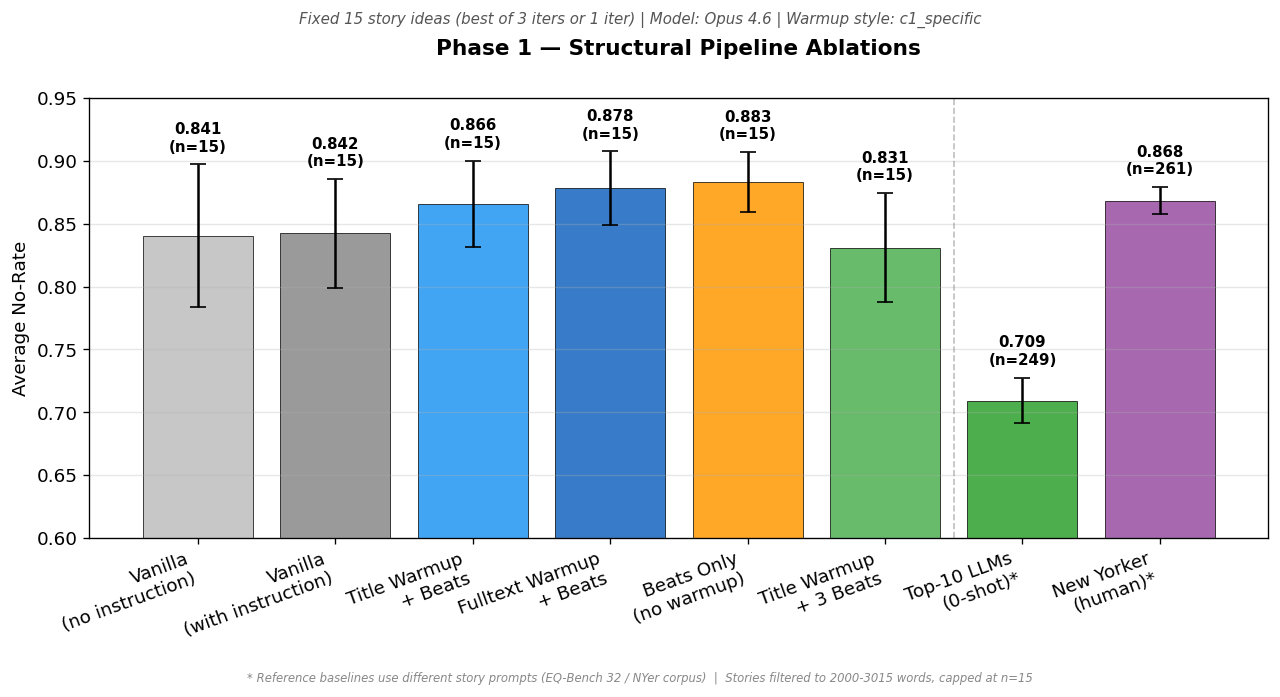

In [70]:
PH1_CONFIGS = ['vanilla', 'instruction_vanilla', 'full_title', 'full_fulltext', 'no_warmup', 'short_beats']
PH1_LABELS = [
    'Vanilla\n(no instruction)',
    'Vanilla\n(with instruction)',
    'Title Warmup\n+ Beats',
    'Fulltext Warmup\n+ Beats',
    'Beats Only\n(no warmup)',
    'Title Warmup\n+ 3 Beats',
]
PH1_COLORS = ['#BDBDBD', '#888888', '#2196F3', '#1565C0', '#FF9800', '#4CAF50']

plot_norate_bars(
    PH1_CONFIGS, PH1_LABELS, PH1_COLORS,
    'Phase 1 — Structural Pipeline Ablations',
    subtitle='Fixed 15 story ideas (best of 3 iters or 1 iter) | Model: Opus 4.6 | Warmup style: c1_specific',
)

## Phase 2 — Beat Count Sweep

**Controlled for:** Fixed 15 story ideas, Opus 4.6, step0 = fulltext warmup (c1_specific)

15 story ideas × 1 iteration = 15 stories per config.
Step0 = fulltext held constant. Varies: --step1-max-beats (unlimited, 10, 5, 3).
Includes vanilla baseline for reference.

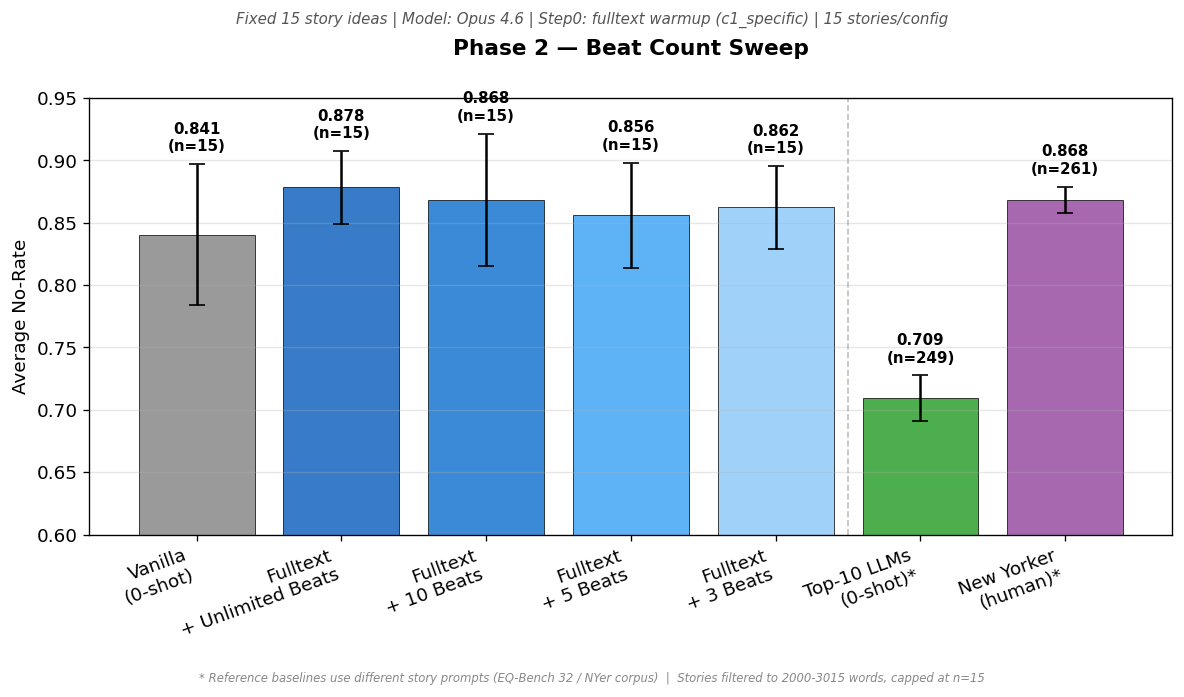

In [71]:
PH2_CONFIGS = ['vanilla', 'full_fulltext', 'fulltext_beats10', 'fulltext_beats5', 'fulltext_beats3']
PH2_LABELS = [
    'Vanilla\n(0-shot)',
    'Fulltext\n+ Unlimited Beats',
    'Fulltext\n+ 10 Beats',
    'Fulltext\n+ 5 Beats',
    'Fulltext\n+ 3 Beats',
]
PH2_COLORS = ['#888888', '#1565C0', '#1976D2', '#42A5F5', '#90CAF9']

plot_norate_bars(
    PH2_CONFIGS, PH2_LABELS, PH2_COLORS,
    'Phase 2 — Beat Count Sweep',
    subtitle='Fixed 15 story ideas | Model: Opus 4.6 | Step0: fulltext warmup (c1_specific) | 15 stories/config',
)

## Phase 3 — Idea Generation Ablations

**Controlled for:** Opus 4.6, step0 = fulltext warmup (c1_specific), step1 = default beats (unlimited). Except `idea_vanilla` which skips step0+step1.

LLM-generated story ideas × 1 iteration = 15 stories per config.
Varies: idea generation components (taxonomy, tropes, genre priming).

| Config | Taxonomy | Tropes | Priming | Trope Selection | Step 1 |
|---|---|---|---|---|---|
| idea_full | ✓ | ✓ | ✓ | LLM-curated | full beats |
| idea_no_priming | ✓ | ✓ | ✗ | LLM-curated | full beats |
| idea_no_tropes | ✓ | ✗ | ✓ | — | full beats |
| idea_tax_only | ✓ | ✗ | ✗ | — | full beats |
| idea_tropes_only | ✗ | ✓ | ✗ | random 2 | full beats |
| idea_bare | ✗ | ✗ | ✗ | — | full beats |
| idea_vanilla | ✓ | ✓ | ✓ | LLM-curated | **none (vanilla)** |

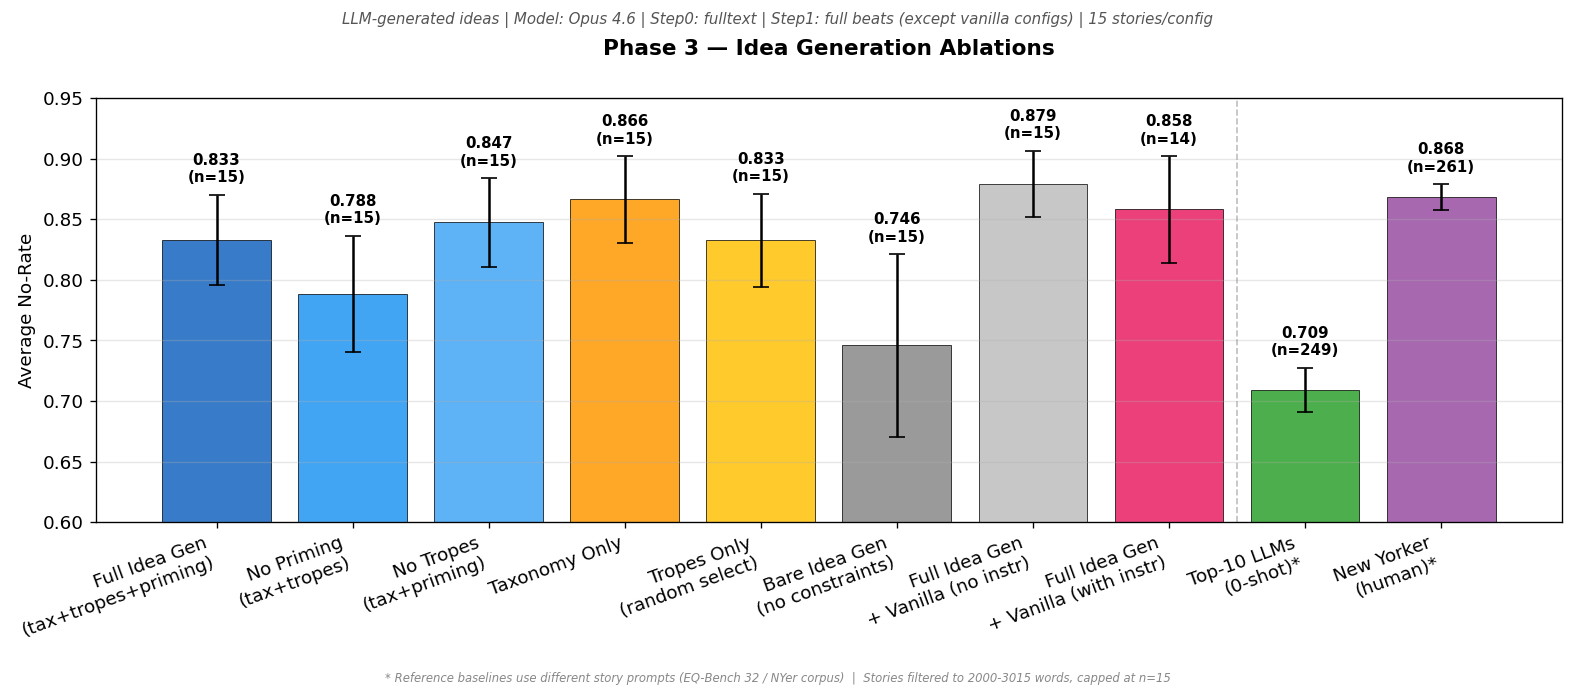

In [72]:
PH3_CONFIGS = [
    'idea_full', 'idea_no_priming', 'idea_no_tropes',
    'idea_tax_only', 'idea_tropes_only', 'idea_bare',
    'idea_vanilla', 'idea_instruction_vanilla',
]
PH3_LABELS = [
    'Full Idea Gen\n(tax+tropes+priming)',
    'No Priming\n(tax+tropes)',
    'No Tropes\n(tax+priming)',
    'Taxonomy Only',
    'Tropes Only\n(random select)',
    'Bare Idea Gen\n(no constraints)',
    'Full Idea Gen\n+ Vanilla (no instr)',
    'Full Idea Gen\n+ Vanilla (with instr)',
]
PH3_COLORS = [
    '#1565C0', '#2196F3', '#42A5F5',
    '#FF9800', '#FFC107',
    '#888888',
    '#BDBDBD', '#E91E63',
]

plot_norate_bars(
    PH3_CONFIGS, PH3_LABELS, PH3_COLORS,
    'Phase 3 — Idea Generation Ablations',
    subtitle='LLM-generated ideas | Model: Opus 4.6 | Step0: fulltext | Step1: full beats (except vanilla configs) | 15 stories/config',
)

## All Phases Combined — Best Config per Phase

Pick the best config from each phase and compare side-by-side.

In [ ]:
# Find best per phase (highest no-rate, filtered by word count, capped at n=15)
def best_config(configs):
    best_id, best_mean = None, -1
    for cfg in configs:
        data = load_judge(cfg)
        if data is None:
            continue
        valid_ids = get_valid_story_ids(cfg)
        vals = per_story_means(data, 'yes_rate', valid_ids)
        if len(vals) == 0:
            continue
        m = np.mean(1.0 - vals)
        if m > best_mean:
            best_id, best_mean = cfg, m
    return best_id

ph1_best = best_config(['vanilla', 'instruction_vanilla',
                         'full_title', 'full_fulltext', 'no_warmup', 'short_beats'])
ph2_best = best_config(['full_fulltext', 'fulltext_beats10', 'fulltext_beats5', 'fulltext_beats3'])
ph3_best = best_config(['idea_full', 'idea_no_priming', 'idea_no_tropes',
                         'idea_tax_only', 'idea_tropes_only', 'idea_bare',
                         'idea_vanilla', 'idea_instruction_vanilla'])

COMBINED = ['instruction_vanilla']
COMBINED_LABELS = ['Vanilla\n(with instruction)']
COMBINED_COLORS = ['#888888']

for label, cfg, color in [
    ('Best Phase 1', ph1_best, '#1565C0'),
    ('Best Phase 2', ph2_best, '#2196F3'),
    ('Best Phase 3', ph3_best, '#E91E63'),
]:
    if cfg and cfg not in COMBINED:
        COMBINED.append(cfg)
        COMBINED_LABELS.append(f'{label}\n({cfg})')
        COMBINED_COLORS.append(color)

print('Best configs:', {f'Phase {i+1}': c for i, c in enumerate([ph1_best, ph2_best, ph3_best])})

plot_norate_bars(
    COMBINED, COMBINED_LABELS, COMBINED_COLORS,
    'Best Config per Phase — No-Rate Comparison',
    subtitle=f'Winner from each phase vs instruction-vanilla | Model: Opus 4.6 | Filtered to {MIN_WORDS}-{MAX_WORDS} words, n<={TARGET_N}',
)

## EQ-Bench Evaluation — Rubric Leaderboard + No-Rate Comparison

Our narrative pipeline (Sonnet 4.6 + precomputed warmup + beats) was also evaluated on the **EQ-Bench Creative Writing v3** benchmark using the standard 32 story prompts. Two complementary views:

**Left:** EQ-Bench rubric score leaderboard (top 10). Our pipeline achieves **84.58/100**, placing it #1 on the rubric leaderboard — above GPT-5.4 (84.45).

**Right:** No-rate comparison on the **same 32 EQ-Bench prompts** — a direct apples-to-apples comparison. Unlike Phases 1–3 (which use our custom 15 story ideas), this comparison uses identical prompts for both vanilla and pipeline stories.

*Note: EQ-Bench stories are shorter (~1000 words per prompt specification) than our custom stories (~2500 words). No word count filter is applied here — all stories are included.*

In [ ]:
# ── Side-by-side: EQ-Bench Rubric Leaderboard + No-Rate on same prompts ────────

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

# ═══════════════════════════════════════════════════════════════════════════════
# LEFT: EQ-Bench Rubric Score Leaderboard (top 10 + ours)
# ═══════════════════════════════════════════════════════════════════════════════

# Website ground truth (from user, March 2026)
leaderboard = [
    ('Narrative Pipeline
(Sonnet 4.6 + beats)', 84.58, True),
    ('GPT-5.4',                                   84.45, False),
    ('GPT-5 (2025-08-07)',                        83.95, False),
    ('Horizon Alpha',                              83.50, False),
    ('GPT-5.2',                                    83.30, False),
    ('Horizon Beta',                               83.30, False),
    ('Claude Opus 4.6',                            82.65, False),
    ('Claude Sonnet 4.6',                          82.50, False),
    ('Kimi-K2 Thinking',                           82.35, False),
    ('Kimi-K2 Instruct',                           82.00, False),
    ('Claude Opus 4.5',                            81.75, False),
]

names = [x[0] for x in leaderboard]
scores = [x[1] for x in leaderboard]
is_ours = [x[2] for x in leaderboard]

y = np.arange(len(names))[::-1]
colors_lb = ['#E91E63' if o else '#90CAF9' for o in is_ours]
edge_lb = ['#C2185B' if o else '#1565C0' for o in is_ours]
lw_lb = [2.5 if o else 0.5 for o in is_ours]

bars1 = ax1.barh(y, scores, color=colors_lb, edgecolor=edge_lb, linewidth=lw_lb, height=0.7)
ax1.set_yticks(y)
ax1.set_yticklabels(names, fontsize=9)
ax1.set_xlabel('Rubric Score (0-100)')
ax1.set_xlim(80, 86)
ax1.set_title('EQ-Bench Creative Writing v3
Rubric Leaderboard (Top 11)', fontsize=12, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

# Annotate scores
for bar, s, o in zip(bars1, scores, is_ours):
    ax1.text(bar.get_width() + 0.08, bar.get_y() + bar.get_height()/2,
             f'{s:.2f}', va='center', fontsize=9,
             fontweight='bold' if o else 'normal',
             color='#C2185B' if o else '#333333')

# ═══════════════════════════════════════════════════════════════════════════════
# RIGHT: No-Rate comparison on EQ-Bench 32 prompts (same stories)
# ═══════════════════════════════════════════════════════════════════════════════

# Load no-rates for CWB configs (no word count filter — EQ-Bench stories are ~1000 words)
cwb_configs = {
    'cwb_vanilla_sonnet46': ('Sonnet 4.6
(vanilla, 0-shot)', '#90CAF9'),
    'cwb_narrative_sonnet46': ('Sonnet 4.6
+ Pipeline (beats)', '#E91E63'),
}

bar_labels_r = []
bar_means_r = []
bar_cis_r = []
bar_colors_r = []
bar_counts_r = []
bar_missing_r = []

for i, (cfg, (label, color)) in enumerate(cwb_configs.items()):
    data = load_judge(cfg)
    if data is None:
        bar_labels_r.append(label)
        bar_means_r.append(0)
        bar_cis_r.append(0)
        bar_colors_r.append(color)
        bar_counts_r.append(0)
        bar_missing_r.append(i)
        continue
    # No word count filter for CWB stories (they target ~1000 words per prompt spec)
    story_means = per_story_means(data, 'yes_rate')
    no_means = 1.0 - story_means
    bar_labels_r.append(label)
    bar_means_r.append(np.mean(no_means))
    bar_cis_r.append(1.96 * np.std(no_means) / np.sqrt(len(no_means)))
    bar_colors_r.append(color)
    bar_counts_r.append(len(no_means))

# Add reference baselines
bar_labels_r.extend(['Top-10 LLMs*
(0-shot)', 'New Yorker*
(human)'])
bar_means_r.extend([REF_LLM_MEAN, REF_NYER_MEAN])
bar_cis_r.extend([REF_LLM_CI, REF_NYER_CI])
bar_colors_r.extend(['#2ca02c', '#984ea3'])
bar_counts_r.extend([len(llm_no_rates), len(nyer_no_rates)])

x2 = np.arange(len(bar_means_r))
bars2 = ax2.bar(x2, bar_means_r, yerr=bar_cis_r, capsize=6,
                color=bar_colors_r, edgecolor='black', linewidth=0.5, alpha=0.85)

# Grey out missing
for i in bar_missing_r:
    bars2[i].set_alpha(0.2)
    bars2[i].set_hatch('//')
    ax2.text(i, 0.55, 'PENDING', ha='center', va='bottom',
             fontsize=8, color='red', fontweight='bold')

# Separator
ax2.axvline(len(cwb_configs) - 0.5, color='gray', linewidth=1, linestyle='--', alpha=0.5)

ax2.set_xticks(x2)
ax2.set_xticklabels(bar_labels_r, rotation=15, ha='right')
ax2.set_ylabel('Average No-Rate')
ax2.set_ylim(0.50, 0.95)
ax2.set_title('No-Rate on EQ-Bench 32 Prompts
(same prompts, direct comparison)', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# Annotate
for i, (bar, m, ci, n) in enumerate(zip(bars2, bar_means_r, bar_cis_r, bar_counts_r)):
    if i in bar_missing_r:
        continue
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + ci + 0.01,
             f'{m:.3f}
(n={n})', ha='center', va='bottom',
             fontsize=10, fontweight='bold')

# Footnote
fig.text(0.5, 0.005,
         '* Top-10 LLMs and NYer baselines use the same 100-ending evaluation pipeline  |  '
         'EQ-Bench stories are ~1000 words (per prompt spec), no word count filter applied',
         ha='center', va='bottom', fontsize=7, color='#888888', style='italic')

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()